# 1. Simulation Walkthrough

A step-by-step look at what `CarlaGymEnv` is actually doing under the hood:
the network starts empty, we push traffic through it, and we watch queues,
throughput, latency and congestion develop over time.

This notebook uses the synthetic Poisson traffic generator (no dataset
needed) so it runs standalone.

In [1]:
import sys, os
REPO_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
os.chdir(REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from carla_gym.env import CarlaGymEnv
from carla_gym.utils.visualization import NetworkVisualizer

plt.rcParams["figure.dpi"] = 100
np.random.seed(0)

## Build the environment and look at the empty network

nodes=9  links=12
observation shape=(33,)  action shape=(24,)


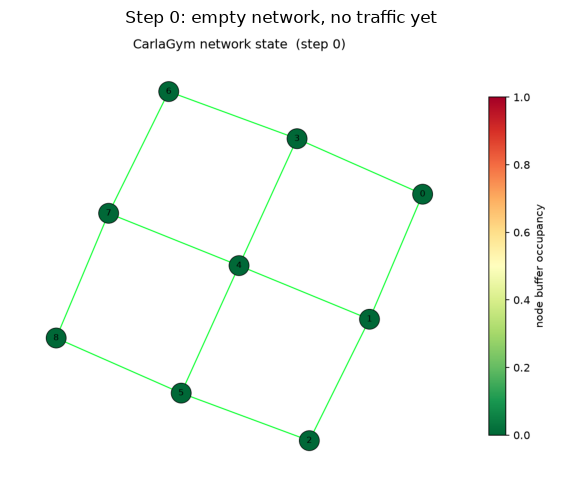

In [2]:
env = CarlaGymEnv(topology="grid", num_nodes=9, link_capacity=30, node_buffer=120,
                  bandwidth_budget=0.8, max_steps=150, seed=0)
obs, info = env.reset(seed=0)

print(f"nodes={env.num_nodes}  links={env.num_edges}")
print(f"observation shape={obs.shape}  action shape={env.action_space.shape}")

viz = NetworkVisualizer(env.network)
viz.render(step=0, save_path="notebooks/_tmp_empty.png")
plt.figure(figsize=(7, 6))
plt.imshow(plt.imread("notebooks/_tmp_empty.png"))
plt.axis("off")
plt.title("Step 0: empty network, no traffic yet")
plt.show()

## The five built-in topologies

Every topology is a NetworkX graph of nodes (routers with finite buffers) and
links (shared bandwidth). Node size and label show the node degree: well-connected
nodes have more ways to forward traffic, poorly connected ones are natural bottlenecks.

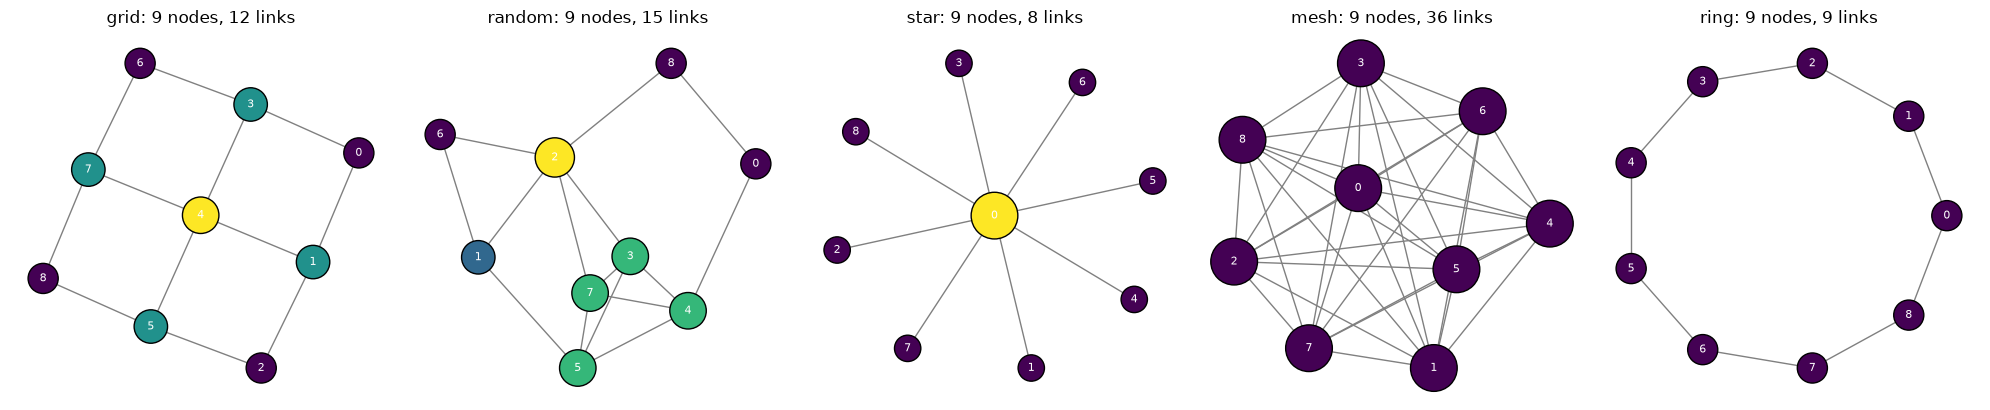

,nodes,links,min degree,max degree,action dim (2E),observation dim (2E+N)
topology,,,,,,
grid,9,12,2,4,24,33
random,9,15,2,5,30,39
star,9,8,1,8,16,25
mesh,9,36,8,8,72,81
ring,9,9,2,2,18,27


In [3]:
import networkx as nx
from carla_gym.core.network import NetworkModel

fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))
rows = []
for ax, topo in zip(axes, NetworkModel.SUPPORTED_TOPOLOGIES):
    net = NetworkModel(topology=topo, num_nodes=9, seed=0)
    g = net.graph
    deg = dict(g.degree())
    pos = nx.spring_layout(g, seed=0) if topo != "ring" else nx.circular_layout(g)
    nx.draw_networkx_edges(g, pos, ax=ax, edge_color="gray")
    nx.draw_networkx_nodes(g, pos, ax=ax, node_color=[deg[n] for n in g], cmap="viridis",
                           node_size=[250 + 110 * deg[n] for n in g], edgecolors="black")
    nx.draw_networkx_labels(g, pos, ax=ax, font_size=8, font_color="white")
    ax.set_title(f"{topo}: {g.number_of_nodes()} nodes, {g.number_of_edges()} links")
    ax.axis("off")
    rows.append({"topology": topo, "nodes": g.number_of_nodes(), "links": g.number_of_edges(),
                 "min degree": min(deg.values()), "max degree": max(deg.values()),
                 "action dim (2E)": 2 * g.number_of_edges(),
                 "observation dim (2E+N)": 2 * g.number_of_edges() + g.number_of_nodes()})
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("topology")

## Run a congestion-aware policy and log every step

We use the `queue_proportional` heuristic from `carla_gym/baselines.py`
so the network experiences realistic load without training anything.

In [4]:
from carla_gym.baselines import policy_queue_proportional

rows = []
obs, _ = env.reset(seed=0)
rng = np.random.default_rng(0)
for t in range(150):
    action = policy_queue_proportional(env, obs, rng)
    obs, reward, terminated, truncated, info = env.step(action)
    rows.append({
        "step": t, "reward": reward,
        "throughput": info["reward_throughput"],
        "delay": info["reward_delay"],
        "loss": info["reward_loss"],
        "deadline_miss": info["reward_deadline_miss"],
        "latency_steps": info["mean_latency_steps"],
        "backlog_units": info["backlog_units"],
        "mean_link_utilization": info["mean_link_utilization"],
    })
    if terminated or truncated:
        break

log = pd.DataFrame(rows)
log.tail()

,step,reward,throughput,delay,loss,deadline_miss,latency_steps,backlog_units,mean_link_utilization
145,145,-0.174611,0.785736,0.635247,0.548974,0.187500,4.214286,298.407484,0.317463
146,146,-0.531252,0.442436,0.674136,0.493763,0.285714,3.272727,304.744476,0.372149
147,147,0.606233,1.000000,0.737534,0.000000,0.050000,8.300000,236.811722,0.479991
148,148,0.379038,0.691255,0.499434,0.000000,0.125000,4.800000,279.473572,0.540923
149,149,-0.003625,0.481423,0.405738,0.246465,0.071429,6.071429,309.935940,0.493339


## Queue backlog and link utilization over time

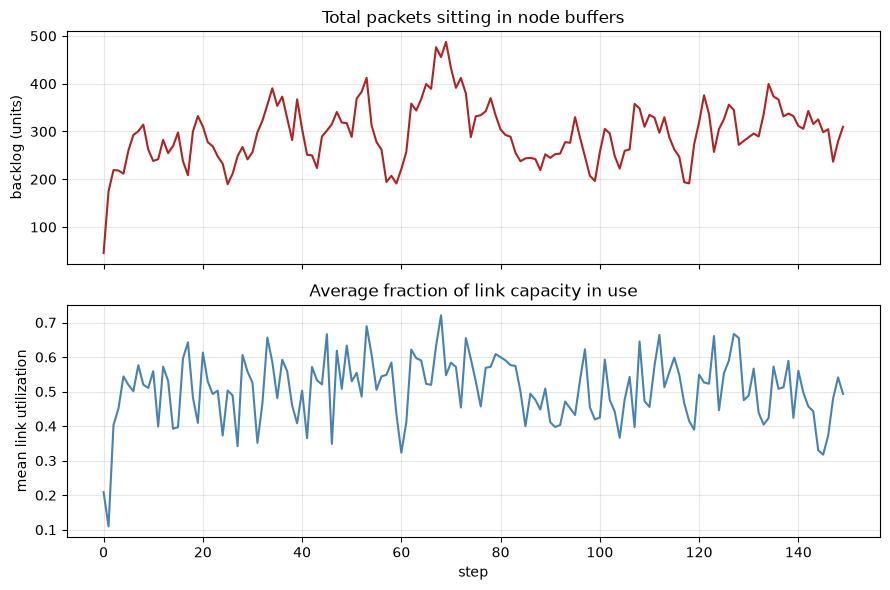

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(log["step"], log["backlog_units"], color="firebrick")
axes[0].set_ylabel("backlog (units)")
axes[0].set_title("Total packets sitting in node buffers")
axes[0].grid(alpha=0.3)

axes[1].plot(log["step"], log["mean_link_utilization"], color="steelblue")
axes[1].set_ylabel("mean link utilization")
axes[1].set_xlabel("step")
axes[1].set_title("Average fraction of link capacity in use")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## The four reward components over time

`R = throughput - k*delay - c*loss - m*deadline_miss`, every term normalized to [0, 1].
The delay term is the sensitivity-weighted age of traffic in the system: delivered
packets contribute their end-to-end delay, queued packets their current age.

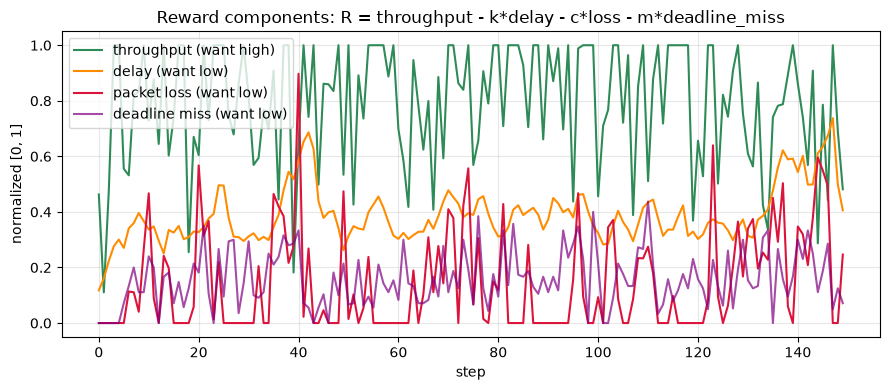

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(log["step"], log["throughput"], label="throughput (want high)", color="seagreen")
ax.plot(log["step"], log["delay"], label="delay (want low)", color="darkorange")
ax.plot(log["step"], log["loss"], label="packet loss (want low)", color="crimson")
ax.plot(log["step"], log["deadline_miss"], label="deadline miss (want low)", color="purple", alpha=0.7)
ax.set_xlabel("step")
ax.set_ylabel("normalized [0, 1]")
ax.set_title("Reward components: R = throughput - k*delay - c*loss - m*deadline_miss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Network state: healthy vs congested

Render the network at an early (lightly loaded) step and a later
(more congested) step, side by side. Edge color/width encodes link
utilization (green -> red), node color/size encodes buffer occupancy.

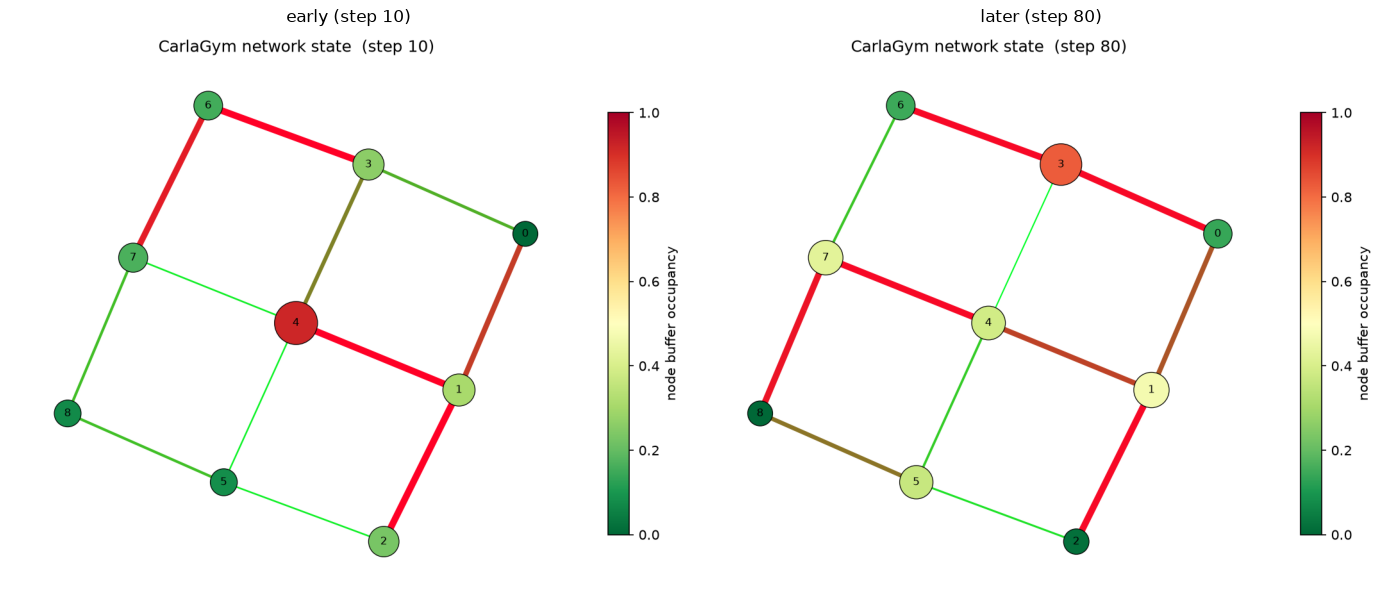

In [7]:
obs, _ = env.reset(seed=0)
rng = np.random.default_rng(0)
snapshots = {}
for t in range(150):
    action = policy_queue_proportional(env, obs, rng)
    obs, reward, terminated, truncated, info = env.step(action)
    if t == 9:
        viz.render(step=t + 1, save_path="notebooks/_tmp_early.png")
        snapshots["early (step 10)"] = "notebooks/_tmp_early.png"
    if t == 79:
        viz.render(step=t + 1, save_path="notebooks/_tmp_late.png")
        snapshots["later (step 80)"] = "notebooks/_tmp_late.png"
    if terminated or truncated:
        break

fig, axes = plt.subplots(1, len(snapshots), figsize=(7 * len(snapshots), 6))
if len(snapshots) == 1:
    axes = [axes]
for ax, (title, path) in zip(axes, snapshots.items()):
    ax.imshow(plt.imread(path))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Zero-bandwidth stress test

To see real congestion build, starve the network entirely (action = 0
everywhere) for a stretch of steps and watch the backlog climb and
every link turn red.

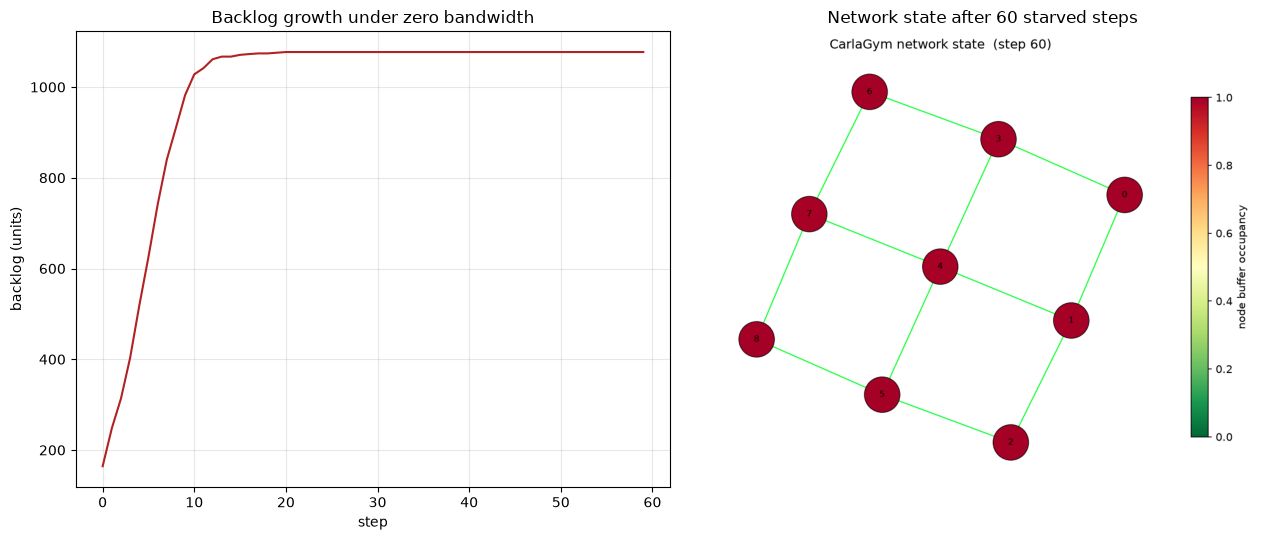

In [8]:
env.reset(seed=1)
backlog_trace = []
for t in range(60):
    action = np.zeros(2 * env.num_edges, dtype=np.float32)
    obs, reward, terminated, truncated, info = env.step(action)
    backlog_trace.append(info["backlog_units"])

viz.render(step=60, save_path="notebooks/_tmp_starved.png")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].plot(backlog_trace, color="firebrick")
axes[0].set_title("Backlog growth under zero bandwidth")
axes[0].set_xlabel("step")
axes[0].set_ylabel("backlog (units)")
axes[0].grid(alpha=0.3)

axes[1].imshow(plt.imread("notebooks/_tmp_starved.png"))
axes[1].set_title("Network state after 60 starved steps")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## `render()` as an image array

With `render_mode="rgb_array"` the environment returns the frame as a NumPy array,
which is what video recorders and Gymnasium wrappers expect.

frame: ndarray (600, 750, 3) uint8


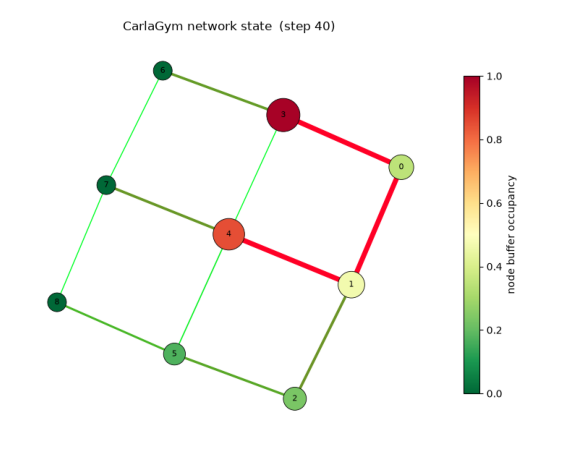

In [9]:
rgb_env = CarlaGymEnv(render_mode="rgb_array", bandwidth_budget=0.8, max_steps=40, seed=0)
obs, _ = rgb_env.reset(seed=0)
for _ in range(40):
    obs, *_ = rgb_env.step(policy_queue_proportional(rgb_env, obs))
frame = rgb_env.render()
print("frame:", type(frame).__name__, frame.shape, frame.dtype)
plt.figure(figsize=(7, 6))
plt.imshow(frame)
plt.axis("off")
plt.show()
rgb_env.close()

## A node bottleneck

`bottlenecks={node: scale}` degrades a node: it keeps only that fraction of its buffer
and of the capacity of every link touching it. Below, the centre node of the grid is
cut to 30%. The same policy on the same traffic now has to cope with a choke point.

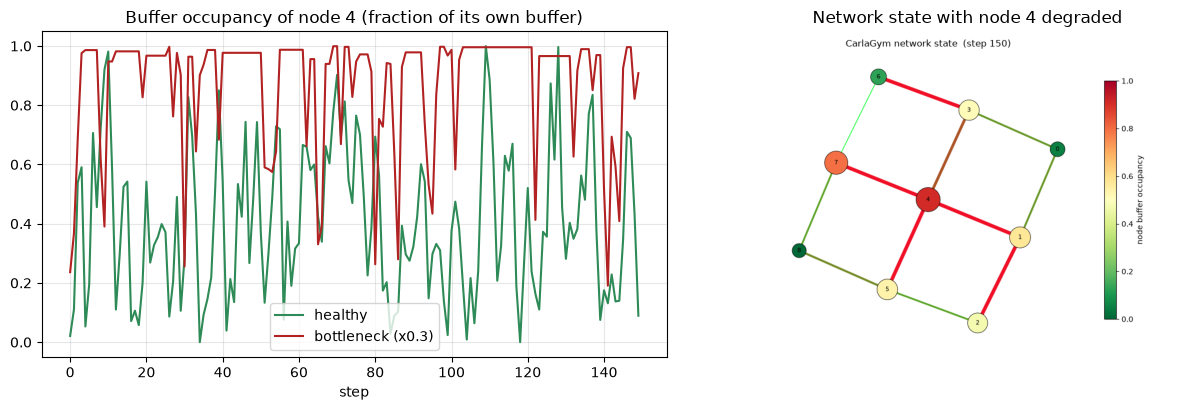

mean reward after warm-up: healthy +0.360, bottleneck -0.509


In [10]:
def run_backlog(bottlenecks):
    e = CarlaGymEnv(bandwidth_budget=0.8, max_steps=150, bottlenecks=bottlenecks, seed=0)
    o, _ = e.reset(seed=0)
    occ, rew = [], []
    for _ in range(150):
        o, r, _, _, _ = e.step(policy_queue_proportional(e, o))
        occ.append(o[-e.num_nodes:].copy()); rew.append(r)
    return np.array(occ), np.array(rew), e

occ_ok, rew_ok, _ = run_backlog(None)
occ_bn, rew_bn, env_bn = run_backlog({4: 0.3})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(occ_ok[:, 4], label="healthy", color="seagreen")
axes[0].plot(occ_bn[:, 4], label="bottleneck (x0.3)", color="firebrick")
axes[0].set_title("Buffer occupancy of node 4 (fraction of its own buffer)")
axes[0].set_xlabel("step"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].imshow(NetworkVisualizer(env_bn.network).render(step=150, return_rgb=True))
axes[1].set_title("Network state with node 4 degraded"); axes[1].axis("off")
plt.tight_layout(); plt.show()
print(f"mean reward after warm-up: healthy {rew_ok[20:].mean():+.3f}, bottleneck {rew_bn[20:].mean():+.3f}")

In [11]:
# cleanup temp render files
import glob
for f in glob.glob("notebooks/_tmp_*.png"):
    os.remove(f)